# PTB-XL Multilabel Classification and Unified ECG Analysis

This notebook explores PTB-XL 1.0.3 and the project's five-category multilabel task, then demonstrates the production data and model interfaces. It does **not** define a competing label mapper or silently train a second model. Long-running training is documented as a CLI command and is not launched by this notebook.

**Intended use:** educational research only; outputs are not diagnoses or medical advice.

## Research questions

1. How are PTB-XL SCP diagnostic codes mapped to NORM, MI, STTC, CD, and HYP?
2. How do those labels and the official patient-aware folds distribute across records?
3. Can the production loader recover finite 12-lead, 1,000-sample 100 Hz signals in the required order?
4. What does the unified shared-encoder model predict after it has been trained and its artifacts have been validated?

PTB-XL labels are multilabel: multiple superclass labels may coexist. The current production policy treats absent target classes as negatives only when at least one diagnostic SCP code maps to a target; records with no mapped target are excluded from supervised training. Review this documented closed-world assumption when interpreting results.

## 1. Environment and reproducibility

In [1]:
from pathlib import Path
import os, sys, platform, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the repository root without a machine-specific absolute path.
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "ptbxl_data.py").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "ptbxl_data.py").is_file():
    raise RuntimeError("Run this notebook from the repository or one of its subdirectories")
sys.path.insert(0, str(ROOT))
DATA_DIR = Path(os.environ.get("HEARTBEAT_PTBXL_DIR", ROOT / "data" / "ptbxl"))
ARTIFACT_DIR = Path(os.environ.get("HEARTBEAT_UNIFIED_ARTIFACTS", ROOT / "artifacts" / "ptbxl_unified" / "v1"))
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print({"python": platform.python_version(), "platform": platform.platform(),
       "repository": str(ROOT), "data_dir": str(DATA_DIR), "artifacts": str(ARTIFACT_DIR)})

{'python': '3.13.1', 'platform': 'Windows-11-10.0.26200-SP0', 'repository': 'C:\\Users\\forda\\OneDrive\\Desktop\\HeartBeat-Sentinel-Explainable-ECG-Anomaly-Detection-Using-an-Autoencoder', 'data_dir': 'C:\\Users\\forda\\OneDrive\\Desktop\\HeartBeat-Sentinel-Explainable-ECG-Anomaly-Detection-Using-an-Autoencoder\\data\\ptbxl', 'artifacts': 'C:\\Users\\forda\\OneDrive\\Desktop\\HeartBeat-Sentinel-Explainable-ECG-Anomaly-Detection-Using-an-Autoencoder\\artifacts\\ptbxl_unified\\v1'}


In [2]:
import torch
from src.ptbxl_data import (
    LEAD_ORDER, TARGET_CATEGORIES, PreprocessingConfig, NormalizationStats,
    load_ptbxl_bundle, load_ptbxl_metadata, load_scp_statements,
    map_scp_codes_to_targets, select_frame, validate_patient_splits,
    read_ptbxl_signal, fit_lead_normalization, normalize_signal,
)
from src.unified_ecg_model import UnifiedECGModel, UnifiedModelConfig
from src.unified_runtime import (
    masked_multilabel_bce_loss, masked_normal_reconstruction_loss,
    normal_mask_from_labels,
)
from src.unified_artifacts import load_unified_artifacts
from src.unified_inference import UnifiedECGInference

print({"torch": torch.__version__, "device": "cuda" if torch.cuda.is_available() else "cpu",
       "targets": list(TARGET_CATEGORIES), "lead_order": list(LEAD_ORDER)})
PREPROCESSING = PreprocessingConfig(sampling_rate=100, sequence_length=1000)
REQUIRED_FILES = [DATA_DIR / "ptbxl_database.csv", DATA_DIR / "scp_statements.csv", DATA_DIR / "records100"]
missing = [str(path) for path in REQUIRED_FILES if not path.exists()]
print("Missing required dataset components:", missing if missing else "none")
BUNDLE = load_ptbxl_bundle(str(DATA_DIR)) if not missing else None

{'torch': '2.14.1+cpu', 'device': 'cpu', 'targets': ['NORM', 'MI', 'STTC', 'CD', 'HYP'], 'lead_order': ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']}
Missing required dataset components: none


## 2. Dataset loading and metadata audit

In [3]:
if BUNDLE is not None:
    metadata = BUNDLE.metadata
    print("metadata shape:", metadata.shape)
    print("columns:", metadata.columns.tolist())
    print("patient count:", metadata.patient_id.nunique())
    print("folds:", sorted(metadata.strat_fold.unique().tolist()))
    print("invalid SCP-code rows:", BUNDLE.stats.get("n_unparsed_scp_codes"))
    print("dataset label policy:", BUNDLE.stats.get("label_mask_semantics"))
    display(metadata[["ecg_id", "patient_id", "strat_fold", "filename_lr", "scp_codes"]].head())
else:
    print("Dataset inspection is pending until all required files are present.")

metadata shape: (21799, 34)
columns: ['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr', 'scp_codes_parsed', 'scp_codes_parsed_ok', 'mapped_scp_codes', 'has_target_labels', 'anomaly_reference', 'split']
patient count: 18869
folds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
invalid SCP-code rows: 0
dataset label policy: A record with at least one mapped diagnostic statement is usable; absence of a target category is an annotated negative. Records with no diagnostic statement are excluded and never treated as negative.


,ecg_id,patient_id,strat_fold,filename_lr,scp_codes
0,1,15709,3,records100/00000/00001_lr,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,13243,2,records100/00000/00002_lr,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,20372,5,records100/00000/00003_lr,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014,3,records100/00000/00004_lr,"{'NORM': 100.0, 'SR': 0.0}"
4,5,17448,4,records100/00000/00005_lr,"{'NORM': 100.0, 'SR': 0.0}"


## 3. Production label mapping and multilabel targets

In [4]:
if BUNDLE is not None:
    print("Target order:", list(TARGET_CATEGORIES))
    print("Positive counts:", BUNDLE.stats.get("positive_counts"))
    print("Usable records:", BUNDLE.stats.get("n_usable_for_supervision"))
    print("Excluded without a mapped diagnostic target:", BUNDLE.stats.get("n_excluded_no_diagnostic_label"))

    # Audit one record through the same production mapper used for BUNDLE.
    statements = BUNDLE.statements
    row = metadata.loc[metadata["has_target_labels"]].iloc[0]
    mapped, matched_codes, diagnostic_details, usable = map_scp_codes_to_targets(
        row["scp_codes_parsed"], statements
    )
    print({"ecg_id": int(row.ecg_id), "usable": usable, "matched_codes": matched_codes,
           "diagnostic_details": diagnostic_details, "labels": dict(zip(TARGET_CATEGORIES, mapped.astype(int)))})

    y = pd.DataFrame(BUNDLE.labels, columns=TARGET_CATEGORIES, index=metadata.index)
    cooccurrence = y.T @ y
else:
    cooccurrence = None

Target order: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Positive counts: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'CD': 4898, 'HYP': 2649}
Usable records: 21388
Excluded without a mapped diagnostic target: 411
{'ecg_id': 1, 'usable': True, 'matched_codes': ['NORM'], 'diagnostic_details': [('NORM', 'NORM', 100.0)], 'labels': {'NORM': np.int64(1), 'MI': np.int64(0), 'STTC': np.int64(0), 'CD': np.int64(0), 'HYP': np.int64(0)}}


## 4. Exploratory data analysis

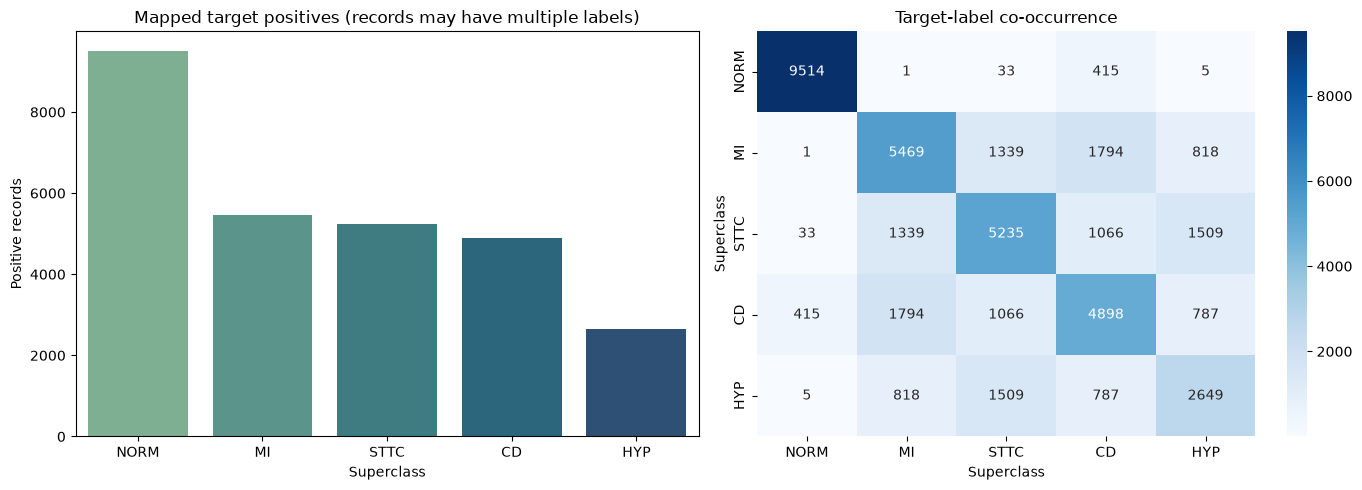

In [5]:
if BUNDLE is not None:
    counts = pd.Series(BUNDLE.labels.sum(axis=0), index=TARGET_CATEGORIES).sort_values(ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=axes[0], palette="crest")
    axes[0].set(title="Mapped target positives (records may have multiple labels)", xlabel="Superclass", ylabel="Positive records")
    sns.heatmap(cooccurrence, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
    axes[1].set(title="Target-label co-occurrence", xlabel="Superclass", ylabel="Superclass")
    plt.tight_layout()
    plt.show()
else:
    print("EDA waits for a complete PTB-XL dataset.")

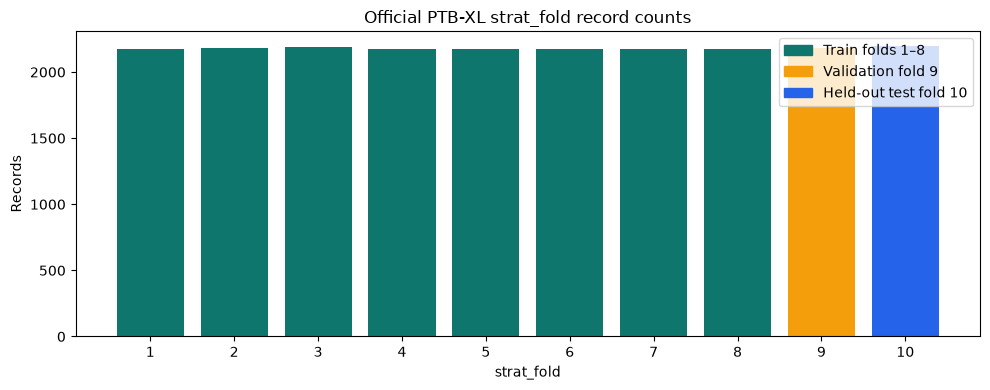

,records
strat_fold,
1,2175
2,2181
3,2192
4,2174
5,2174
6,2173
7,2176
8,2173
9,2183


In [6]:
if BUNDLE is not None:
    fold_counts = metadata.groupby("strat_fold").size().reindex(range(1, 11), fill_value=0)
    split_names = {**{fold: "Train" for fold in range(1, 9)}, 9: "Validation", 10: "Test"}
    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(fold_counts.index.astype(str), fold_counts.values, color=["#0f766e"] * 8 + ["#f59e0b", "#2563eb"])
    ax.set(title="Official PTB-XL strat_fold record counts", xlabel="strat_fold", ylabel="Records")
    for bar, fold in zip(bars, fold_counts.index):
        bar.set_label(split_names[int(fold)])
    ax.legend(handles=[plt.Rectangle((0,0),1,1,color="#0f766e",label="Train folds 1–8"),
                       plt.Rectangle((0,0),1,1,color="#f59e0b",label="Validation fold 9"),
                       plt.Rectangle((0,0),1,1,color="#2563eb",label="Held-out test fold 10")])
    plt.tight_layout(); plt.show()
    display(fold_counts.rename("records").to_frame())

In [7]:
if BUNDLE is not None:
    split_rows = []
    for split in ("train", "val", "test"):
        frame, labels, mask = select_frame(BUNDLE, split, require_labels=True)
        split_rows.append({"split": split, "records": len(frame), "patients": frame.patient_id.nunique(),
                           **{category: int(labels[:, i].sum()) for i, category in enumerate(TARGET_CATEGORIES)}})
    split_summary = pd.DataFrame(split_rows).set_index("split")
    display(split_summary)
    print("Patient split check:", validate_patient_splits(metadata, metadata["split"].fillna("excluded").tolist()))

,records,patients,NORM,MI,STTC,CD,HYP
split,,,,,,,
train,17084,14823,7596,4379,4186,3907,2119
val,2146,1917,955,540,528,495,268
test,2158,1877,963,550,521,496,262


Patient split check: {'counts': {'train': 17418, 'val': 2183, 'test': 2198}, 'patient_counts': {'train': 15023, 'val': 1942, 'test': 1904}, 'leakage': {}}


## 5. Real waveform inspection and preprocessing

In [8]:
example_signal = None
example_row = None
if BUNDLE is not None:
    train_norm, train_y, train_mask = select_frame(BUNDLE, "train", require_labels=True, normal_only=True)
    if len(train_norm):
        example_row = train_norm.iloc[0]
        example_signal = read_ptbxl_signal(
            str(DATA_DIR), example_row["filename_lr"], sampling_rate=100, expected_length=1000
        )
        assert example_signal.shape == (12, 1000)
        assert np.isfinite(example_signal).all()
        print({"ecg_id": int(example_row.ecg_id), "path": example_row.filename_lr,
               "shape": example_signal.shape, "finite": bool(np.isfinite(example_signal).all()),
               "sampling_rate_hz": 100, "units": "mV"})
    else:
        print("No usable normal training record was found.")
else:
    print("Waveform display is pending until PTB-XL is available.")

{'ecg_id': 1, 'path': 'records100/00000/00001_lr', 'shape': (12, 1000), 'finite': True, 'sampling_rate_hz': 100, 'units': 'mV'}


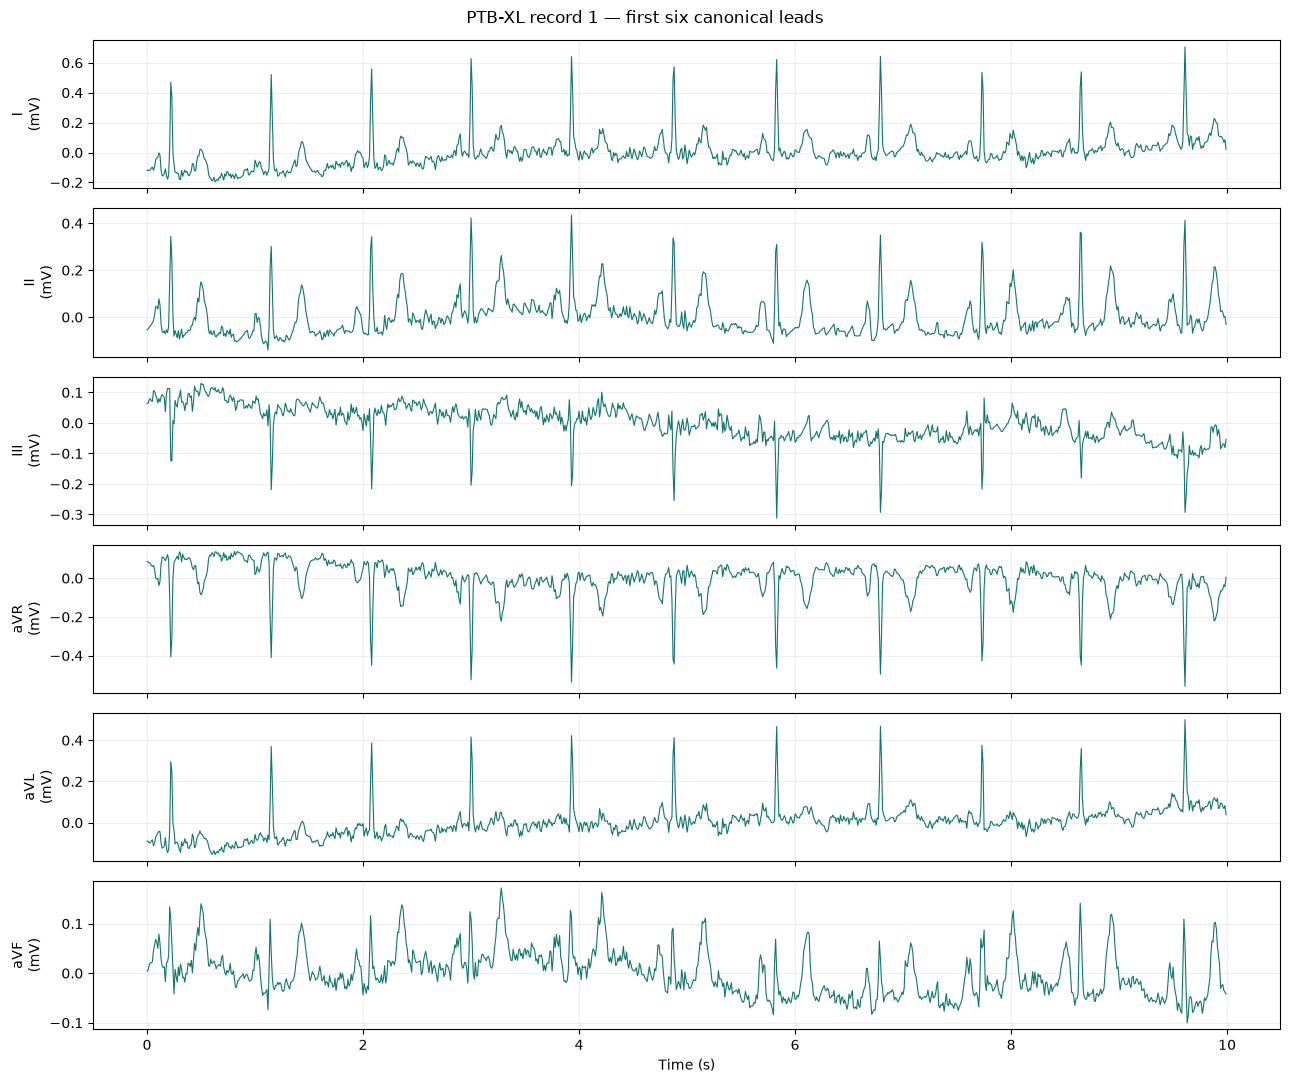

In [9]:
if example_signal is not None:
    time_seconds = np.arange(example_signal.shape[1]) / 100.0
    fig, axes = plt.subplots(6, 1, figsize=(13, 11), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(time_seconds, example_signal[i], linewidth=0.8, color="#0f766e")
        ax.set_ylabel(f"{LEAD_ORDER[i]}\n(mV)")
        ax.grid(alpha=0.2)
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(f"PTB-XL record {int(example_row.ecg_id)} — first six canonical leads")
    plt.tight_layout(); plt.show()

## 6. Train/validation/test protocol and normalization

The production split assigns folds 1–8 to training, fold 9 to validation, and fold 10 to final testing, and checks patient separation. The example below fits statistics on a small **training-only normal subset** only to demonstrate the production API; it is not the full training artifact normalization.

{'demo_fit_records': 2, 'normalization_mode': 'train_lead_zscore', 'normalized_shape': (12, 1000), 'finite': True, 'warning': 'illustration only; full training fits stats over its configured training-normal set'}


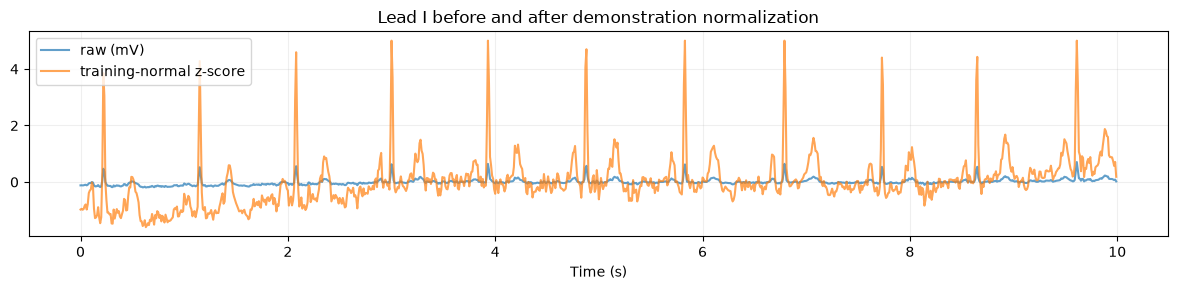

In [10]:
demo_stats = None
if BUNDLE is not None and example_signal is not None:
    # This small demonstration fit is deliberately restricted to training-fold normal records.
    from itertools import islice
    from src.ptbxl_data import load_signals_for_frame
    demo_frame = train_norm.iloc[:2].reset_index(drop=True)
    demo_stats = fit_lead_normalization(
        load_signals_for_frame(demo_frame, str(DATA_DIR), PREPROCESSING), max_records=2
    )
    processed = normalize_signal(example_signal, demo_stats)
    print({"demo_fit_records": len(demo_frame), "normalization_mode": demo_stats.mode,
           "normalized_shape": processed.shape, "finite": bool(np.isfinite(processed).all()),
           "warning": "illustration only; full training fits stats over its configured training-normal set"})
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(np.arange(1000) / 100, example_signal[0], label="raw (mV)", alpha=.7)
    ax.plot(np.arange(1000) / 100, processed[0], label="training-normal z-score", alpha=.7)
    ax.set(xlabel="Time (s)", title=f"Lead {LEAD_ORDER[0]} before and after demonstration normalization")
    ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

## 7. Baseline and unified model

This repository currently implements the unified shared-encoder architecture rather than a separately trained baseline classifier. No baseline metrics are claimed. The model has a 1D CNN encoder, reconstruction decoder, and five-logit multilabel head. Training uses masked `BCEWithLogitsLoss`; inference applies independent sigmoid scores, not softmax.

In [11]:
if example_signal is not None and demo_stats is not None:
    x = torch.from_numpy(normalize_signal(example_signal, demo_stats)).unsqueeze(0)
    shape_model = UnifiedECGModel(UnifiedModelConfig(encoder_channels=(8, 16, 32), classifier_hidden=16, dropout=0.0))
    shape_model.eval()
    with torch.no_grad():
        output = shape_model(x)
    print({"input": tuple(x.shape), "reconstruction": tuple(output.reconstruction.shape),
           "classification_logits": tuple(output.classification_logits.shape),
           "sigmoid_scores": tuple(shape_model.predict_scores(x).shape)})

{'input': (1, 12, 1000), 'reconstruction': (1, 12, 1000), 'classification_logits': (1, 5), 'sigmoid_scores': (1, 5)}


## 8. Real-record batch/loss/gradient smoke test (opt-in)

Set `RUN_REAL_BATCH_SMOKE = True` to load a small batch of actual training-fold records, calculate the production masked losses, backpropagate, and take one optimizer step. This is a technical smoke test, not training or evaluation.

In [12]:
RUN_REAL_BATCH_SMOKE = False  # opt in explicitly; uses real WFDB records
if RUN_REAL_BATCH_SMOKE:
    from src.ptbxl_data import make_dataloader
    frame, labels, mask = select_frame(BUNDLE, "train", require_labels=True, normal_only=True)
    frame, labels, mask = frame.iloc[:2].reset_index(drop=True), labels[:2], mask[:2]
    stats = fit_lead_normalization(
        load_signals_for_frame(frame, str(DATA_DIR), PREPROCESSING), max_records=2
    )
    batch = next(iter(make_dataloader(frame, labels, mask, str(DATA_DIR), PREPROCESSING, stats,
                                      batch_size=2, shuffle=False, num_workers=0)))
    model = UnifiedECGModel(UnifiedModelConfig(encoder_channels=(8, 16, 32), classifier_hidden=16, dropout=0.0))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    result = model(batch["signal"].float())
    cls_loss = masked_multilabel_bce_loss(result.classification_logits, batch["labels"], batch["label_mask"])
    rec_loss = masked_normal_reconstruction_loss(result.reconstruction, batch["signal"],
                                                 normal_mask_from_labels(batch["labels"], batch["label_mask"]))
    total = cls_loss + 0.5 * rec_loss
    total.backward(); optimizer.step()
    assert torch.isfinite(total)
    print({"ecg_ids": batch["ecg_id"].tolist(), "loss": float(total.detach()), "one_optimizer_step": "passed"})
else:
    print("Skipped by default. This notebook cell does not claim training has run.")

Skipped by default. This notebook cell does not claim training has run.


## 9. Full training and validation-only threshold calibration

Use the repository CLI for reproducible staged training. It fits preprocessing on the training partition, selects thresholds on validation fold 9, and saves versioned artifacts. The default full command can be long on CPU; run it from PowerShell only after reviewing machine capacity. This notebook does not start it.

In [13]:
TRAIN_COMMAND = (
    "python -m src.train_unified_model all "
    "--data-dir data/ptbxl --out-dir artifacts/ptbxl_unified/v1 "
    "--cache-dir data/ptbxl_cache --device cpu"
)
print(TRAIN_COMMAND)
print("Default trainer: 40 epochs per stage with early stopping patience 8; no training is launched here.")

python -m src.train_unified_model all --data-dir data/ptbxl --out-dir artifacts/ptbxl_unified/v1 --cache-dir data/ptbxl_cache --device cpu
Default trainer: 40 epochs per stage with early stopping patience 8; no training is launched here.


## 10. Training curves and threshold calibration

Training history and threshold tuning outputs exist only after the corresponding CLI stages run. Do not synthesize or prefill loss curves. The validation-only tuning command is: `python -m src.train_unified_model tune --data-dir data/ptbxl --out-dir artifacts/ptbxl_unified/v1 --cache-dir data/ptbxl_cache`.

In [14]:
history_path = ARTIFACT_DIR / "training_history.json"
if history_path.is_file():
    import json
    history = json.loads(history_path.read_text(encoding="utf-8"))
    print("Saved training history keys:", list(history))
else:
    print("Training history pending: no unified checkpoint has been trained in this artifact directory.")

Saved training history keys: ['train_classification_loss', 'train_normal_reconstruction_loss', 'train_total_loss', 'val_classification_loss', 'val_macro_f1', 'val_normal_reconstruction_loss', 'val_total_loss']


## 11. Held-out evaluation

Final evaluation uses fold 10 only after thresholds are frozen from fold 9. The evaluator saves machine-readable JSON and plots. No held-out metrics are shown until those files exist.

In [15]:
evaluation_path = ARTIFACT_DIR / "evaluation_test.json"
if evaluation_path.is_file():
    import json
    evaluation = json.loads(evaluation_path.read_text(encoding="utf-8"))
    display(pd.json_normalize(evaluation, sep="."))
else:
    print("Held-out test metrics pending; no evaluation_test.json is present.")
print("Command after training and validation tuning:")
print("python -m src.unified_evaluate --artifacts artifacts/ptbxl_unified/v1 --data-dir data/ptbxl --cache-dir data/ptbxl_cache --split test")

,artifact_dir,evaluated_utc,label_order,model_version,separation_note,split,thresholds_frozen,anomaly.accuracy,anomaly.auroc,anomaly.confusion.fn,...,dataset.stats.positive_counts.NORM,dataset.stats.positive_counts.STTC,dataset.stats.split_summary.counts.test,dataset.stats.split_summary.counts.train,dataset.stats.split_summary.counts.val,dataset.stats.split_summary.patient_counts.test,dataset.stats.split_summary.patient_counts.train,dataset.stats.split_summary.patient_counts.val,dataset.stats.target_order,dataset.version
0,C:\Users\forda\OneDrive\Desktop\HeartBeat-Sent...,2026-10-28T01:09:49.724391+00:00,"[NORM, MI, STTC, CD, HYP]",1.0.0,Anomaly scores are reconstruction errors; cond...,test,True,0.531974,0.635522,957,...,9514,5235,2198,17418,2183,1904,15023,1942,"[NORM, MI, STTC, CD, HYP]",1.0.3


Command after training and validation tuning:
python -m src.unified_evaluate --artifacts artifacts/ptbxl_unified/v1 --data-dir data/ptbxl --cache-dir data/ptbxl_cache --split test


## 12. Explainability

The production service exposes original/reconstructed waveforms and pointwise reconstruction errors for anomaly analysis, plus temporal occlusion sensitivity for classification. Occlusion shows how model scores change when a time window is perturbed; it is a model sensitivity explanation, not causal evidence or a clinical finding.

In [16]:
print("Production explanation method: temporal occlusion (src/unified_explain.py).")
print("Anomaly explanation: original signal, reconstruction, pointwise squared error, and frozen anomaly threshold.")
print("A trained artifact is required before these can be demonstrated as model outputs.")

Production explanation method: temporal occlusion (src/unified_explain.py).
Anomaly explanation: original signal, reconstruction, pointwise squared error, and frozen anomaly threshold.
A trained artifact is required before these can be demonstrated as model outputs.


## 13. Real held-out record inference (artifact-dependent)

In [17]:
if BUNDLE is not None and ARTIFACT_DIR.exists():
    test_frame, _, _ = select_frame(BUNDLE, "test", require_labels=True)
    if len(test_frame):
        test_row = test_frame.iloc[0]
        test_signal = read_ptbxl_signal(str(DATA_DIR), test_row["filename_lr"], sampling_rate=100, expected_length=1000)
        service = UnifiedECGInference(str(ARTIFACT_DIR), device="cpu", load_now=True)
        result = service.analyze(test_signal, source=f"ptbxl_test_record:{int(test_row.ecg_id)}")
        print({"ecg_id": int(test_row.ecg_id), "anomaly_score": result.get("anomaly_score"),
               "classification": result.get("category_scores")})
    else:
        print("No labeled test records are available.")
else:
    print("Real held-out inference pending: train and save the unified artifact first.")

{'ecg_id': 9, 'anomaly_score': 0.2709823411387844, 'classification': {'NORM': 0.9758903419125166, 'MI': 0.12904189801694982, 'STTC': 0.005115862080557588, 'CD': 0.014367297129885147, 'HYP': 4.577145586938691e-05}}


## 14. Conclusions and limitations

No experiment results are embedded in this notebook. Populate conclusions only after training and held-out evaluation actually complete. Important limitations include PTB-XL label noise and the production closed-world absent-label assumption; class imbalance; external-domain shift; normalization and threshold dependence; and the fact that reconstruction error does not identify a disease. Outputs are research predictions, not a diagnosis.

## 15. Reproduction guide

Run from the repository root using the project environment:

```powershell
.\.venv\Scripts\Activate.ps1
python -m src.prepare_ptbxl --data-dir data/ptbxl --check-files 20
python -m src.prepare_ptbxl --data-dir data/ptbxl --build-cache --cache-dir data/ptbxl_cache
python -m src.train_unified_model all --data-dir data/ptbxl --out-dir artifacts/ptbxl_unified/v1 --cache-dir data/ptbxl_cache
python -m src.train_unified_model tune --data-dir data/ptbxl --out-dir artifacts/ptbxl_unified/v1 --cache-dir data/ptbxl_cache
python -m src.unified_evaluate --artifacts artifacts/ptbxl_unified/v1 --data-dir data/ptbxl --cache-dir data/ptbxl_cache --split both
```

The dataset and artifacts are local and gitignored. Run all notebook cells for metadata/EDA and lightweight real-record inspection. Training, the optional gradient step, and inference require explicit action or trained artifacts.